In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería (notebooks/colecciones/<coleccion>/ -> ../../../src)
sys.path.append(os.path.abspath('../../../src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

In [2]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el proyecto cuyo cuadro de prelaciones y duraciones (en semanas) se adjunta.

In [3]:
pregunta_1 = "1. Calcule para cada actividad sus fechas más tempranas y más tardías de inicio y fin, y sus holguras total, libre e independiente.  "
pregunta_2 = "2. Determine el camino crítico. ¿Cuántas rutas críticas tiene el proyecto?  "
pregunta_3 = "3. ¿Qué actividades pueden retrasarse sin afectar ni al plazo del proyecto ni al inicio más temprano de ninguna otra actividad? ¿Cuáles pueden retrasarse sin afectar al plazo pero obligando a retrasar a alguna sucesora? Justifíquelo con las holguras.  "
pregunta_4 = "4. La actividad C se retrasa tanto como permite su holgura total (3 semanas). Compruebe que el plazo no cambia y determine qué ocurre con las fechas y holguras de sus sucesoras.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Calcule para cada actividad sus fechas más tempranas y más tardías de inicio y fin, y sus holguras total, libre e independiente.  

2. Determine el camino crítico. ¿Cuántas rutas críticas tiene el proyecto?  

3. ¿Qué actividades pueden retrasarse sin afectar ni al plazo del proyecto ni al inicio más temprano de ninguna otra actividad? ¿Cuáles pueden retrasarse sin afectar al plazo pero obligando a retrasar a alguna sucesora? Justifíquelo con las holguras.  

4. La actividad C se retrasa tanto como permite su holgura total (3 semanas). Compruebe que el plazo no cambia y determine qué ocurre con las fechas y holguras de sus sucesoras.  

In [4]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration
    ('A'     , '---'      , 4       ),
    ('B'     , 'A'        , 7       ),
    ('C'     , '---'      , 4       ),
    ('D'     , 'B'        , 1       ),
    ('E'     , 'C'        , 5       ),
    ('F'     , 'D,E'      , 6       ),
    ('G'     , 'E'        , 1       ),
    ('H'     , 'F'        , 1       ),
    ('I'     , 'G'        , 6       ),
], columns=['activity', 'predecessor', 'duration']).set_index('activity')
datos_enunciado

,predecessor,duration
activity,,
A,---,4
B,A,7
C,---,4
D,B,1
E,C,5
F,"D,E",6
G,E,1
H,F,1
I,G,6


# Resolución

In [5]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()

## Apartado 1

In [6]:
display(Markdown(pregunta_1))

1. Calcule para cada actividad sus fechas más tempranas y más tardías de inicio y fin, y sus holguras total, libre e independiente.  

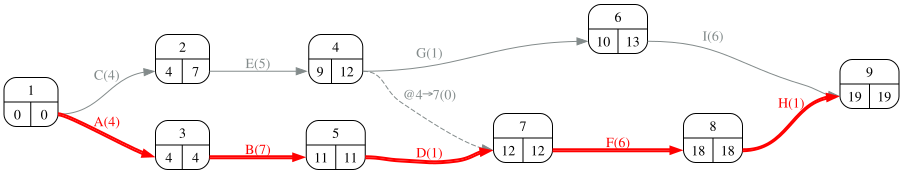

In [7]:
#| fig-cap: "Grafo PERT con tiempos de los nodos y camino crítico"
#| label: fig-pert
proyecto.pert(durations=datos_proyecto['duration'], ranksep=1)

Con las fechas de cada actividad (ES, EF, LS, LF) y las de sus vecinas se definen las tres holguras:

- **Total**: $H_t = LS - ES = LF - EF$. Retraso máximo sin alargar el proyecto, suponiendo que las predecesoras acaban lo antes posible y las sucesoras pueden empezar lo más tarde posible.
- **Libre**: $H_l = \min_{s \in suc} ES_s - EF$. Retraso máximo sin mover el inicio más temprano de ninguna sucesora.
- **Independiente**: $H_i = \max\bigl(0,\ \min_{s \in suc} ES_s - \max_{p \in pred} LF_p - D\bigr)$. Retraso disponible incluso si las predecesoras acaban lo más tarde posible y las sucesoras deben empezar lo antes posible.

Siempre $H_t \ge H_l \ge H_i$.

In [8]:
#| tbl-cap: "Calendario y holguras del proyecto"
#| label: tbl-calendario
calendario = proyecto.calendar(datos_proyecto['duration'])
calendario

,inicio_mas_temprano,inicio_mas_tardio,fin_mas_temprano,fin_mas_tardio,H_libre,H_independiente,H_total,duracion
activity,,,,,,,,
A,0,0,4,4,0,0,0,4
B,4,4,11,11,0,0,0,7
C,0,3,4,7,0,0,3,4
D,11,11,12,12,0,0,0,1
E,4,7,9,12,0,0,3,5
F,12,12,18,18,0,0,0,6
G,9,12,10,13,0,0,3,1
H,18,18,19,19,0,0,0,1
I,10,13,16,19,3,0,3,6


## Apartado 2

In [9]:
display(Markdown(pregunta_2))

2. Determine el camino crítico. ¿Cuántas rutas críticas tiene el proyecto?  

In [10]:
duracion_proyecto = proyecto.duration(datos_proyecto['duration'])
rutas_criticas = proyecto.critical_path(datos_proyecto['duration'])
for nombre, acts in rutas_criticas.items():
    print(f'{nombre}: {" - ".join(acts)}')
Markdown(f'La duración del proyecto es {duracion_proyecto} semanas y hay {len(rutas_criticas)} ruta(s) crítica(s). '
         'Las actividades críticas son las de holgura total nula; cuando varias rutas comparten la duración máxima, '
         'todas ellas son críticas y un retraso en cualquiera alarga el proyecto.')

Route_1: A - B - D - F - H


La duración del proyecto es 19 semanas y hay 1 ruta(s) crítica(s). Las actividades críticas son las de holgura total nula; cuando varias rutas comparten la duración máxima, todas ellas son críticas y un retraso en cualquiera alarga el proyecto.

## Apartado 3

In [11]:
display(Markdown(pregunta_3))

3. ¿Qué actividades pueden retrasarse sin afectar ni al plazo del proyecto ni al inicio más temprano de ninguna otra actividad? ¿Cuáles pueden retrasarse sin afectar al plazo pero obligando a retrasar a alguna sucesora? Justifíquelo con las holguras.  

In [12]:
sin_afectar_a_nadie = calendario.index[calendario['H_libre'] > 0].tolist()
solo_sucesoras = calendario.index[(calendario['H_total'] > calendario['H_libre'])].tolist()
Markdown(f'''
- Pueden retrasarse (hasta su holgura libre) sin mover a ninguna otra actividad: **{", ".join(sin_afectar_a_nadie)}**.
- Tienen holgura total mayor que la libre, así que agotar la total obliga a retrasar sucesoras aunque el plazo se mantenga: **{", ".join(solo_sucesoras)}**.
''')


- Pueden retrasarse (hasta su holgura libre) sin mover a ninguna otra actividad: **I**.
- Tienen holgura total mayor que la libre, así que agotar la total obliga a retrasar sucesoras aunque el plazo se mantenga: **C, E, G**.


In [13]:
#| tbl-cap: "Actividades cuyo retraso repercute en sus sucesoras"
#| label: tbl-holgurasDistintas
calendario.loc[solo_sucesoras, ['H_total', 'H_libre', 'H_independiente']]

,H_total,H_libre,H_independiente
activity,,,
C,3,0,0
E,3,0,0
G,3,0,0


## Apartado 4

In [14]:
display(Markdown(pregunta_4))

4. La actividad C se retrasa tanto como permite su holgura total (3 semanas). Compruebe que el plazo no cambia y determine qué ocurre con las fechas y holguras de sus sucesoras.  

Un retraso de C igual a su holgura total equivale a alargar su duración en 3 semanas. Recalculamos el calendario con esa duración.

In [15]:
duraciones_retraso = datos_proyecto['duration'].copy()
duraciones_retraso['C'] += 3
calendario_retraso = proyecto.calendar(duraciones_retraso)
sucesoras = sorted(s for s, ps in prelaciones.immediate_predecessor.items() if 'C' in ps)
comparacion = pd.concat({'antes': calendario.loc[sucesoras, ['inicio_mas_temprano', 'H_total', 'H_libre']],
                         'después': calendario_retraso.loc[sucesoras, ['inicio_mas_temprano', 'H_total', 'H_libre']]}, axis=1)
comparacion

antes                             después          \
         inicio_mas_temprano H_total H_libre inicio_mas_temprano H_total   
activity                                                                   
E                          4       3       0                   7       0   

                  
         H_libre  
activity          
E              0

In [16]:
Markdown(f'La duración del proyecto sigue siendo {proyecto.duration(duraciones_retraso)} semanas, '
         f'pero C ha consumido holgura que compartía con sus sucesoras: las que tenían inicio más temprano '
         f'anterior al nuevo fin de C se retrasan y su holgura total se reduce; alguna pasa a ser crítica.')

La duración del proyecto sigue siendo 19 semanas, pero C ha consumido holgura que compartía con sus sucesoras: las que tenían inicio más temprano anterior al nuevo fin de C se retrasan y su holgura total se reduce; alguna pasa a ser crítica.